# hiNiche on single-cell spatial data (multi-slice): mouse brain MERFISH

> **Environment:** run this notebook in the main **`hiNiche`** environment (`environment.yml`).

This notebook applies hiNiche (`hiNiche_img`, cell → niche) to the MERFISH mouse brain aging dataset, which contains many coronal slices.

All slices are stored in **one AnnData**; `adata.obs[SAMPLE_KEY]` identifies the slice of each cell. Graphs and niches are built **within each slice**, all slices are **trained jointly**, and the resulting cell / niche embeddings are written back to the same AnnData. Niche clusters are evaluated against the annotated brain regions (`adata.obs[LABEL_KEY]`).

## 1. Imports

In [4]:
import config
import utils
import model
from train import run_train_img

import anndata as ad
import scanpy as sc
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import os
import glob
import warnings
import json
from tqdm import tqdm

from sklearn.metrics import normalized_mutual_info_score, adjusted_rand_score
from sklearn.cluster import KMeans

%load_ext autoreload
%autoreload 2

warnings.filterwarnings("ignore")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Configuration

Data paths, the slice column (`SAMPLE_KEY`), the ground-truth columns, the patch root directory (`PATCH_ROOT`) and model / training hyperparameters.

In [5]:
SAMPLE = "Mouse_brain_merfish_multi_slices"

# Data paths: a single AnnData containing all slices (raw counts in adata.raw)
h5_path      = f"DATA/{SAMPLE}/MERFISH_Aging.h5ad"
SAMPLE_KEY   = "slice_id"      # adata.obs column identifying the slice of each cell
LABEL_KEY    = "tissue"        # ground-truth brain region (used for evaluation)
CELLTYPE_KEY = "cell_type"     # cell-type annotation (used for visualization)

# Patch root directory: each slice is cached in its own sub-directory PATCH_ROOT/<slice name>
PATCH_ROOT = f"DATA/{SAMPLE}/mini_batch_cache"

# Model save path (if the file exists, the model is loaded and training is skipped)
MODEL_SAVE_DIR = f"DATA/{SAMPLE}/checkpoint.pt"

# Model / training hyperparameters
single_patch = True    # each slice is used as a single patch
n_pcs       = 30
graph_knn   = 12
niche_knn   = 20
hidden_dim  = 32
lr          = 0.005
num_epochs  = 100
edge_drop   = 0.5
member_drop = 0.5
neg_samples = 5
tau         = 1
seed        = 42
n_clusters  = 7        # number of annotated regions in LABEL_KEY
device      = "cuda:0"

## 3. Load data

Read the AnnData containing all slices. The slices (`SAMPLES`) are taken from `adata.obs[SAMPLE_KEY]`, and each slice gets its own patch directory (`PATCH_LOC`).

In [6]:
adata = sc.read(h5_path)
adata.var_names_make_unique()

# Slices read from adata.obs[SAMPLE_KEY] (in order of appearance); training slice index i <-> SAMPLES[i]
SAMPLES = list(pd.unique(adata.obs[SAMPLE_KEY]))

# Patch save paths: one directory per slice, aligned with SAMPLES
PATCH_LOC = [os.path.join(PATCH_ROOT, str(s)) for s in SAMPLES]

print(f"{len(SAMPLES)} slices, {adata.n_obs} cells, {adata.n_vars} genes")
print(adata.obs[SAMPLE_KEY].value_counts().loc[SAMPLES])

31 slices, 376107 cells, 374 genes
slice_id
MsBrainAgingSpatialDonor_1-0     21000
MsBrainAgingSpatialDonor_2-1     24408
MsBrainAgingSpatialDonor_2-0     15522
MsBrainAgingSpatialDonor_3-1     15492
MsBrainAgingSpatialDonor_3-0     19093
MsBrainAgingSpatialDonor_4-1     11035
MsBrainAgingSpatialDonor_4-2     10853
MsBrainAgingSpatialDonor_4-0      9570
MsBrainAgingSpatialDonor_5-0     10612
MsBrainAgingSpatialDonor_5-2      8830
MsBrainAgingSpatialDonor_5-1      9644
MsBrainAgingSpatialDonor_6-0      9462
MsBrainAgingSpatialDonor_6-1      8014
MsBrainAgingSpatialDonor_6-2      8145
MsBrainAgingSpatialDonor_7-2     11316
MsBrainAgingSpatialDonor_7-1     10604
MsBrainAgingSpatialDonor_7-0     10733
MsBrainAgingSpatialDonor_8-0     14043
MsBrainAgingSpatialDonor_8-1     12110
MsBrainAgingSpatialDonor_8-2     12014
MsBrainAgingSpatialDonor_9-2     10215
MsBrainAgingSpatialDonor_9-1     12292
MsBrainAgingSpatialDonor_9-0     11115
MsBrainAgingSpatialDonor_10-0     9577
MsBrainAgingSpatialD

## 4. Build graphs, niches and mini-batches per slice

For each slice: normalize + log1p the raw counts, scale + PCA, build KNN niches (`niche_knn` cells per niche), the cell graph (expression PCA KNN) and the niche graph (spatial KNN), then cache the slice as a single block in its own directory `PATCH_LOC[i]`.

In [7]:
# ===== Per-slice preprocessing + block construction =====
# Graphs and niches are built within each slice (no cross-slice edges);
# slice SAMPLES[i] is cached in PATCH_LOC[i].
sample_number_list = []

for s, save_dir in zip(SAMPLES, PATCH_LOC):
    adata_s = adata[adata.obs[SAMPLE_KEY] == s].copy()
    adata_s.layers["counts"] = adata_s.raw.X.copy()
    adata_s.X = adata_s.raw.X.copy()
    sc.pp.normalize_total(adata_s, target_sum=1e4)
    sc.pp.log1p(adata_s)

    X_backup = adata_s.X.copy()
    sc.pp.scale(adata_s)
    sc.tl.pca(adata_s, n_comps=n_pcs)
    adata_s.X = X_backup

    adata_s.obsm["X_input"] = adata_s.X
    adata_s.obsm["X_mle"] = adata_s.layers["counts"]
    spatial_coords_px = adata_s.obsm["spatial"]

    # Each niche = a center cell and its niche_knn nearest cells (including itself)
    S_c2n_all, _, _ = utils.build_cell_niche_mapping_knn(spatial_coords_px, k_niche = niche_knn)

    cell_edges = utils.build_spot_knn_graph(adata_s.obsm["X_pca"], graph_knn)    # cell graph: expression (PCA) KNN
    niche_edges = utils.build_spot_knn_graph(spatial_coords_px, graph_knn)       # niche graph: spatial KNN
    batch_mask, block_ids = utils.make_cell_block_masks(spatial_coords_px, S_c2n = S_c2n_all, single_patch = single_patch)

    # Remove old blocks, otherwise the loader would also read leftovers from a previous run
    for f in glob.glob(os.path.join(save_dir, "block_*.pt")):
        os.remove(f)
    utils.build_cell_subgraph_data(adata_s, ref_matrix = None,
                               cell_edges = cell_edges,
                               niche_edges = niche_edges,
                               S_c2n_all = S_c2n_all,
                               batch_mask = batch_mask,
                               block_ids = block_ids,
                               save_dir = save_dir)

    sample_number_list.append({"cell": S_c2n_all.shape[0], "niche": S_c2n_all.shape[1]})
    del adata_s

[Log] Active niches: 21000, Cells per niche (k): 20
[Log] 411274 edges generated from 21000 nodes (k=12)
[Log] 280964 edges generated from 21000 nodes (k=12)


[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:00<00:00,  1.71it/s]


[Log] saved 1 cell blocks → DATA/Mouse_brain_merfish_multi_slices/mini_batch_cache/MsBrainAgingSpatialDonor_1-0
[Log] Active niches: 24408, Cells per niche (k): 20
[Log] 492900 edges generated from 24408 nodes (k=12)
[Log] 328768 edges generated from 24408 nodes (k=12)


[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:00<00:00,  1.68it/s]


[Log] saved 1 cell blocks → DATA/Mouse_brain_merfish_multi_slices/mini_batch_cache/MsBrainAgingSpatialDonor_2-1
[Log] Active niches: 15522, Cells per niche (k): 20
[Log] 311920 edges generated from 15522 nodes (k=12)
[Log] 208420 edges generated from 15522 nodes (k=12)


[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:00<00:00,  2.59it/s]


... (53 outputs left out)

[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:00<00:00,  2.57it/s]


[Log] saved 1 cell blocks → DATA/Mouse_brain_merfish_multi_slices/mini_batch_cache/MsBrainAgingSpatialDonor_12-1
[Log] Active niches: 17502, Cells per niche (k): 20
[Log] 353282 edges generated from 17502 nodes (k=12)
[Log] 234480 edges generated from 17502 nodes (k=12)


[Log] Building & saving cell mini-batches: 100%|██████████| 1/1 [00:00<00:00,  2.04it/s]

[Log] saved 1 cell blocks → DATA/Mouse_brain_merfish_multi_slices/mini_batch_cache/MsBrainAgingSpatialDonor_12-0


## 5. Joint multi-slice training

All slices are trained together. If `MODEL_SAVE_DIR` already exists, the model is loaded and training is skipped. Embeddings are written to `adata.obsm["X_cell_emb"]` and `adata.obsm["X_niche_emb"]`.

In [8]:
# ===== Joint multi-slice training: sample_number_list and PATCH_LOC are lists aligned with SAMPLES =====
emb_all, slice_ids = run_train_img(sample_number_list,
                                   PATCH_LOC = PATCH_LOC,
                                   MODEL_SAVE_DIR = MODEL_SAVE_DIR,
                                   ref_matrix = None,
                                   lr = lr,
                                   in_dim = adata.n_vars,
                                   hidden_dim = hidden_dim,
                                   num_epochs = num_epochs,
                                   edge_drop = edge_drop,
                                   member_drop = member_drop,
                                   neg_samples = neg_samples,
                                   tau = tau,
                                   seed = seed,
                                   device = device)

# Write the embeddings back to the single adata (rows of slice i -> cells of SAMPLES[i], same order).
# With KNN niches every cell is a niche center, so niche embeddings are aligned with cells as well.
adata.obsm["X_cell_emb"]  = np.zeros((adata.n_obs, hidden_dim), dtype=np.float32)
adata.obsm["X_niche_emb"] = np.zeros((adata.n_obs, hidden_dim), dtype=np.float32)
for i, s in enumerate(SAMPLES):
    mask = (adata.obs[SAMPLE_KEY] == s).values
    adata.obsm["X_cell_emb"][mask]  = emb_all["cell"][slice_ids["cell"] == i].detach().cpu().numpy()
    adata.obsm["X_niche_emb"][mask] = emb_all["niche"][slice_ids["niche"] == i].detach().cpu().numpy()

Epoch 100: 100%|██████████| 31/31 [00:00<00:00, 35.65it/s, cl=2.7640]


Training finished!
Model saved to DATA/Mouse_brain_merfish_multi_slices/checkpoint.pt


generating embeddings (slice 30)...: 100%|██████████| 1/1 [00:00<00:00, 17.20it/s]


## 6. Clustering and visualization

KMeans on the cell and niche embeddings within each slice, plotted next to the annotated cell types and brain regions. Labels are stored in `adata.obs["kmeans_cell"]` / `adata.obs["kmeans_niche"]` (comparable only within a slice).

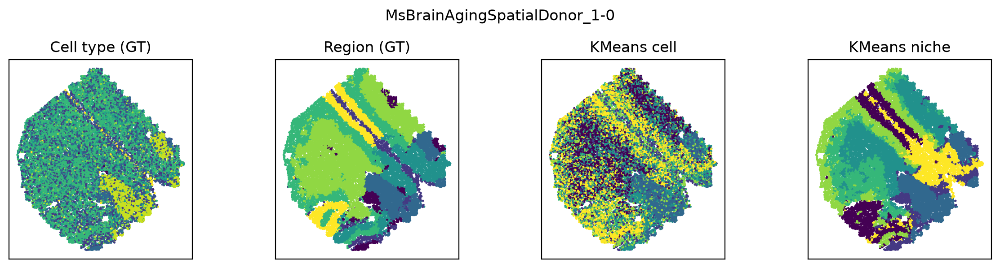

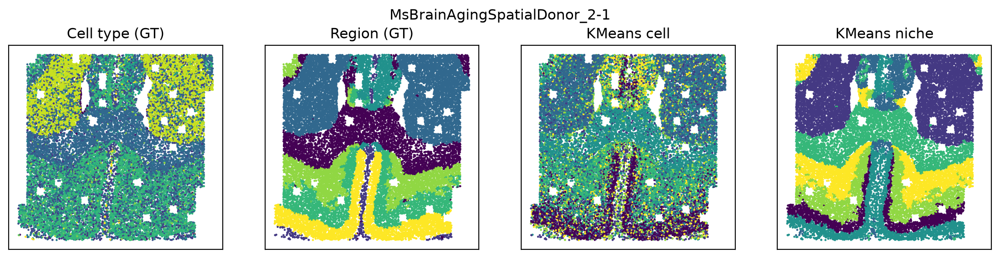

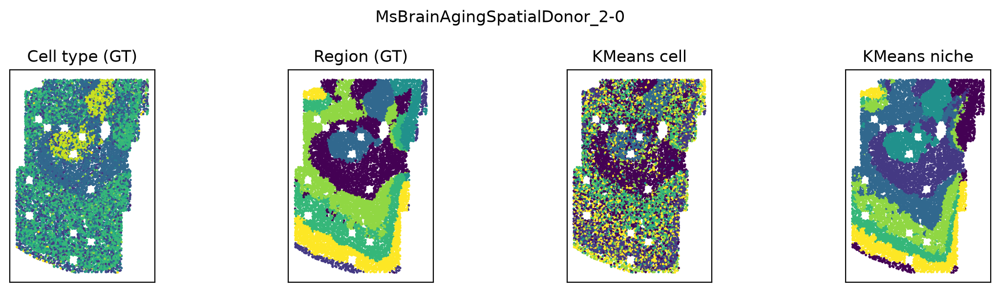

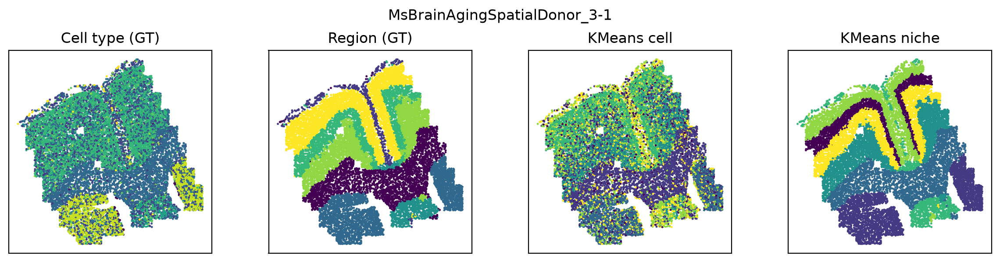

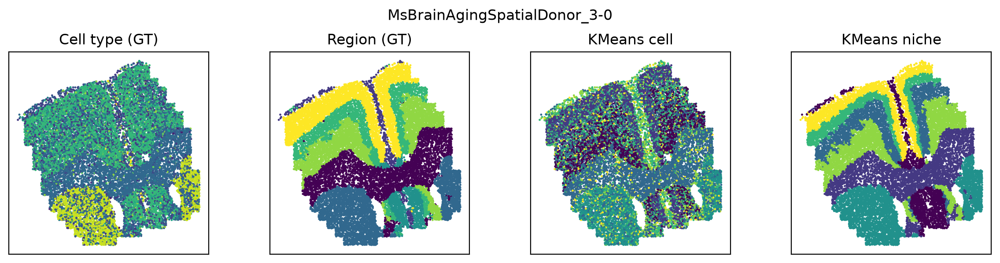

...

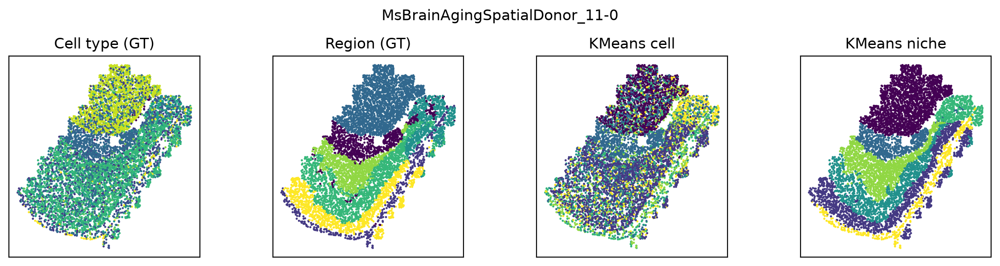

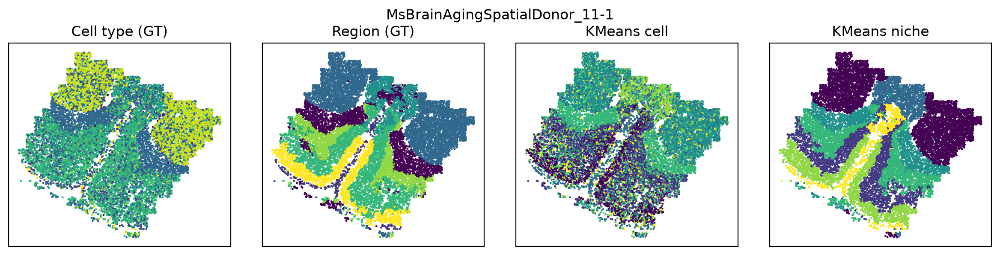

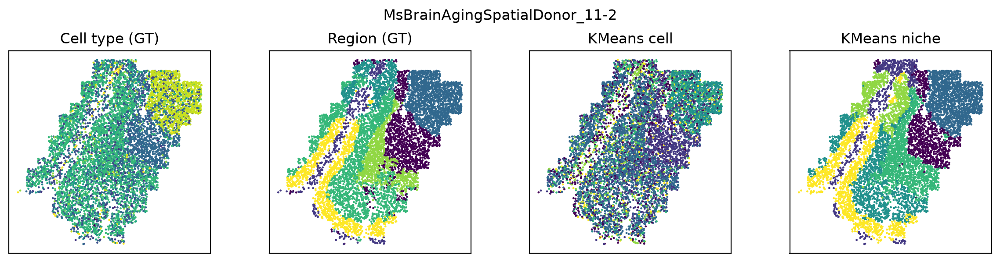

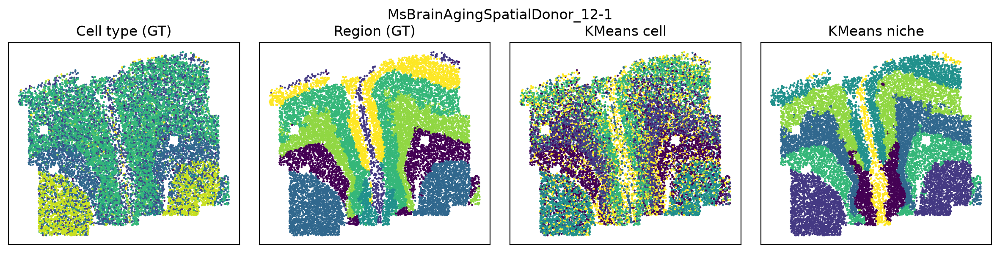

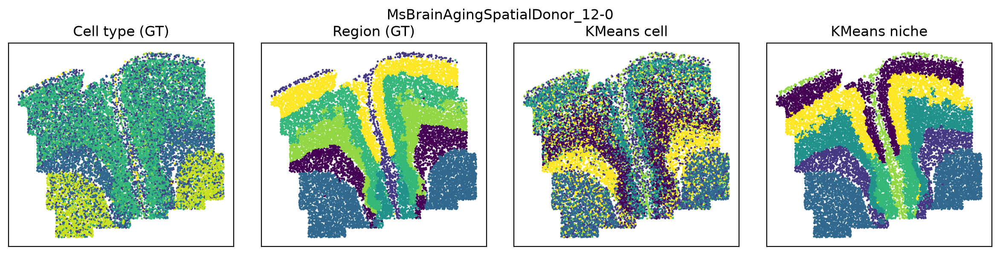

In [9]:
results_cell = {}
results_niche = {}
niche_save = {}

kmeans_cell  = np.empty(adata.n_obs, dtype=object)
kmeans_niche = np.empty(adata.n_obs, dtype=object)

for i, s in enumerate(SAMPLES):
    mask = (adata.obs[SAMPLE_KEY] == s).values
    sub = adata[mask]
    spatial = sub.obsm["spatial"]
    x, y = spatial[:, 0], spatial[:, 1]

    X_cell  = np.asarray(sub.obsm["X_cell_emb"])
    X_niche = np.asarray(sub.obsm["X_niche_emb"])

    # KMeans is run separately within each slice
    labels_cell  = KMeans(n_clusters=n_clusters, random_state=42, n_init=20).fit_predict(X_cell)
    labels_niche = KMeans(n_clusters=n_clusters, random_state=42, n_init=20).fit_predict(X_niche)

    kmeans_cell[mask]  = labels_cell.astype(str)
    kmeans_niche[mask] = labels_niche.astype(str)

    # Ground-truth labels
    point_size = 3
    celltype = sub.obs[CELLTYPE_KEY].astype("category")
    region = sub.obs[LABEL_KEY].astype("category")

    fig, axes = plt.subplots(1, 4, figsize=(12, 3), dpi=200)
    panels = [(celltype.cat.codes, "Cell type (GT)"),
              (region.cat.codes,   "Region (GT)"),
              (labels_cell,        "KMeans cell"),
              (labels_niche,       "KMeans niche")]
    for ax, (c, title) in zip(axes, panels):
        ax.scatter(x, y, c=c, s=point_size, linewidths=0)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_aspect("equal")
        ax.set_title(title)
    fig.suptitle(s)
    plt.tight_layout()
    plt.show()

    true_labels = sub.obs[LABEL_KEY]
    nmi_cell  = normalized_mutual_info_score(true_labels, labels_cell)
    ari_cell  = adjusted_rand_score(true_labels, labels_cell)
    nmi_niche = normalized_mutual_info_score(true_labels, labels_niche)
    ari_niche = adjusted_rand_score(true_labels, labels_niche)

    results_cell[s]  = [nmi_cell, ari_cell]
    results_niche[s] = [nmi_niche, ari_niche]
    niche_save[s]    = pd.Series(labels_niche.astype(str), index=sub.obs_names, dtype="category")

# Per-slice cluster labels stored in the single adata (labels are only comparable within a slice)
adata.obs["kmeans_cell"]  = pd.Categorical(kmeans_cell)
adata.obs["kmeans_niche"] = pd.Categorical(kmeans_niche)

## 7. Evaluation (NMI / ARI)

Agreement of the cell and niche clusters with the annotated brain regions, per slice and averaged.

In [10]:
slice_list = SAMPLES

# Per-slice results
for s in slice_list:
    nmi_c, ari_c = results_cell[s]
    nmi_n, ari_n = results_niche[s]
    print(s)
    print(f"Cell:  NMI: {nmi_c:.4f}, ARI: {ari_c:.4f}")
    print(f"Niche: NMI: {nmi_n:.4f}, ARI: {ari_n:.4f}")

cell_arr  = np.array([results_cell[s]  for s in slice_list], dtype=float)   # [S, 2]
niche_arr = np.array([results_niche[s] for s in slice_list], dtype=float)   # [S, 2]

cell_mean_nmi,  cell_mean_ari  = cell_arr.mean(axis=0)
niche_mean_nmi, niche_mean_ari = niche_arr.mean(axis=0)

print(f"Cell (mean):  NMI: {cell_mean_nmi:.4f}, ARI: {cell_mean_ari:.4f}")
print(f"Niche(mean): NMI: {niche_mean_nmi:.4f}, ARI: {niche_mean_ari:.4f}")

MsBrainAgingSpatialDonor_1-0
Cell:  NMI: 0.2041, ARI: 0.1457
Niche: NMI: 0.5927, ARI: 0.5155
MsBrainAgingSpatialDonor_2-1
Cell:  NMI: 0.3103, ARI: 0.3092
Niche: NMI: 0.7569, ARI: 0.8070
MsBrainAgingSpatialDonor_2-0
Cell:  NMI: 0.2432, ARI: 0.2080
Niche: NMI: 0.7043, ARI: 0.6450
MsBrainAgingSpatialDonor_3-1
Cell:  NMI: 0.3287, ARI: 0.2868
Niche: NMI: 0.8076, ARI: 0.7755
MsBrainAgingSpatialDonor_3-0
Cell:  NMI: 0.3255, ARI: 0.2899
Niche: NMI: 0.7883, ARI: 0.7719
MsBrainAgingSpatialDonor_4-1
Cell:  NMI: 0.3046, ARI: 0.3244
Niche: NMI: 0.8098, ARI: 0.8823
MsBrainAgingSpatialDonor_4-2
Cell:  NMI: 0.2700, ARI: 0.2915
Niche: NMI: 0.8070, ARI: 0.8641
MsBrainAgingSpatialDonor_4-0
Cell:  NMI: 0.1668, ARI: 0.1734
Niche: NMI: 0.6007, ARI: 0.4120
MsBrainAgingSpatialDonor_5-0
Cell:  NMI: 0.2570, ARI: 0.2387
Niche: NMI: 0.7409, ARI: 0.7587
MsBrainAgingSpatialDonor_5-2
Cell:  NMI: 0.2587, ARI: 0.2586
Niche: NMI: 0.7794, ARI: 0.8264
MsBrainAgingSpatialDonor_5-1
Cell:  NMI: 0.1178, ARI: 0.1048
Niche: NM

## 8. Summary plot

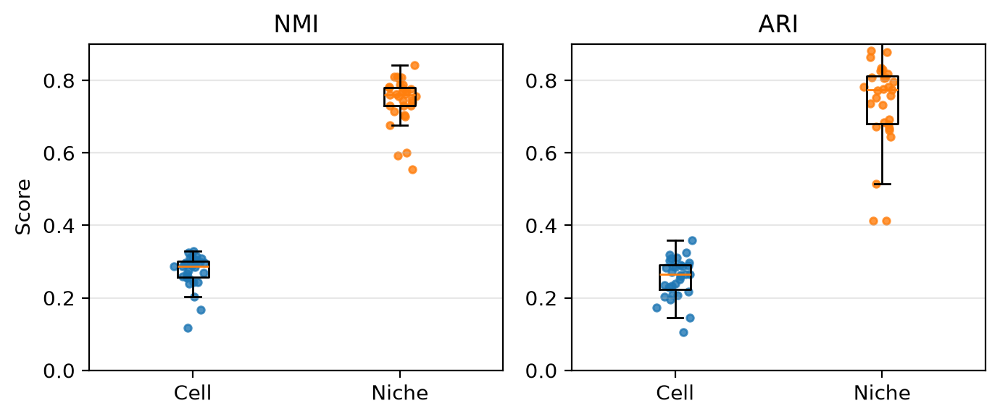

In [11]:
cell_nmi, cell_ari   = cell_arr[:, 0], cell_arr[:, 1]
niche_nmi, niche_ari = niche_arr[:, 0], niche_arr[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(7, 3), dpi=200)
rng = np.random.default_rng(0)

for ax, (c_vals, n_vals, title) in zip(axes, [(cell_nmi, niche_nmi, "NMI"),
                                             (cell_ari, niche_ari, "ARI")]):
    ax.boxplot([c_vals, n_vals], tick_labels=["Cell", "Niche"], showfliers=False)
    ax.scatter(1 + rng.normal(0, 0.04, size=len(c_vals)), c_vals, s=12, alpha=0.8)
    ax.scatter(2 + rng.normal(0, 0.04, size=len(n_vals)), n_vals, s=12, alpha=0.8)
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
    ax.set_ylim(0, 0.9)
    ax.set_yticks(np.arange(0, 0.9 + 1e-9, 0.2))
axes[0].set_ylabel("Score")

plt.tight_layout()
plt.show()